In [2]:
%cd "C:/Users/11584/Desktop/OMGroup/ESE023/Assignment_03"
import os
import numpy as np
import pandas as pd
import netCDF4 as nc
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Show plots in the notebook
%matplotlib inline

C:\Users\11584\Desktop\OMGroup\ESE023\Assignment_03


{'standard_name': 'dry_atmosphere_mole_fraction_of_methane', 'long_name': 'column-average dry-air mole fraction of atmospheric methane', 'units': '1', 'cell_methods': 'time: mean', 'fill_value': np.float64(1e+20), 'comment': 'Satellite retrieved column-average dry-air mole fraction of atmospheric methane (XCH4)'}
ppb


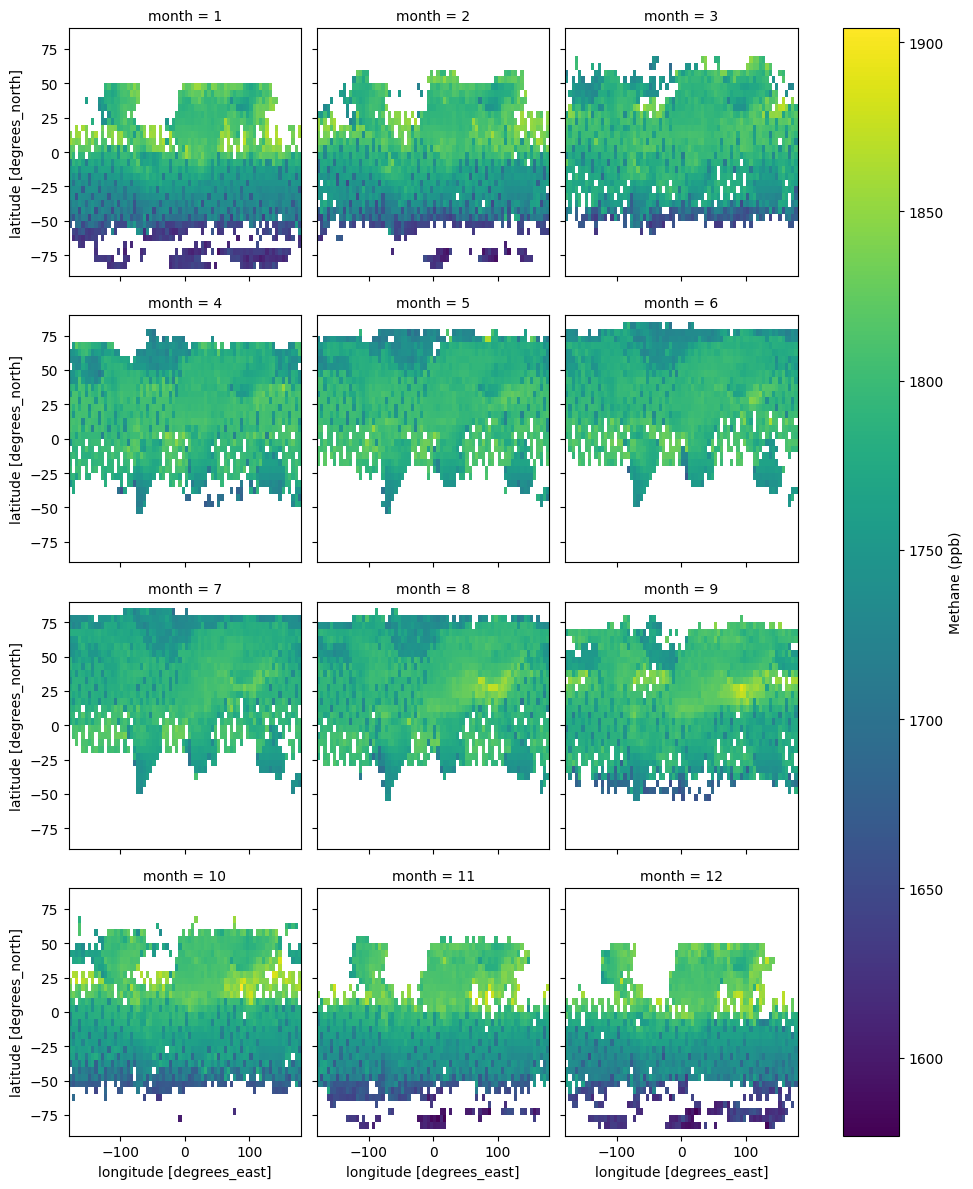

In [29]:
## 1.1  methane climatology
data = xr.open_dataset(
    r"200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc",
    engine="netcdf4"
)


time = data['time']
lat = data['lat']
lon = data['lon']
## .attrs data attributes to check the original unit
print(data["xch4"].attrs)
## transfer unit
methane = data['xch4'].where(data["xch4"] < 1e19) * 1e9
methane.attrs['units'] = 'ppb'
print(methane.attrs["units"])

##compute climatology
climatology = methane.groupby("time.month").mean(
    dim="time", skipna=True, keep_attrs=True
)
plot = climatology.plot(
    x="lon",
    y="lat",
    col="month",
    col_wrap=3,
#    cmap = 'Blues'
)
# color bar settings
plot.cbar.set_label("Methane (ppb)")
plt.show()

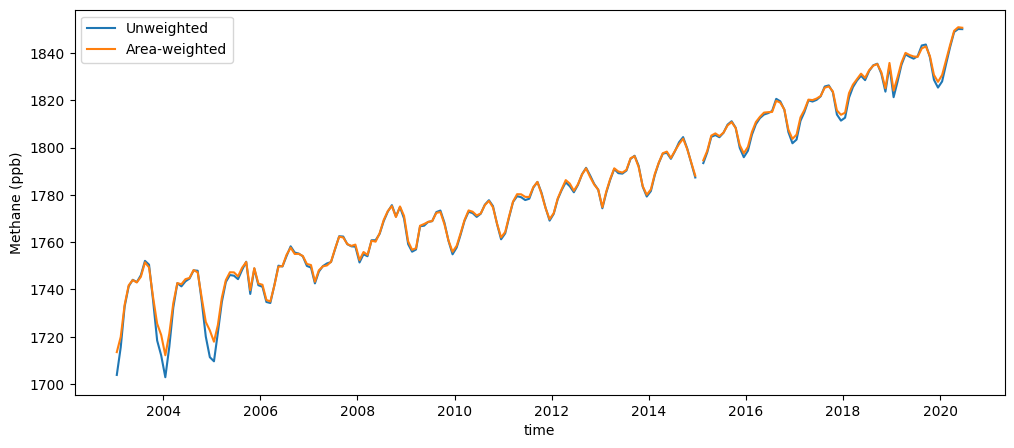

In [41]:
## 1.2  time series
## 筛选时间范围
time2 = data["time"].sel(time=slice("2003-01", "2020-06"))
methane2 = methane.sel(time=time2)

##考虑投影效应，应该按纬度调整面积权重
## 计算时间序列，按经纬度降维
## 比较两种计算方式的差异，发现未加权高估了波动
plt.figure(figsize=(12, 5))
unweighted = methane2.mean(dim=["lat", "lon"])
weighted = methane2.weighted(weights).mean(dim=["lat", "lon"])

unweighted.plot(label="Unweighted")
weighted.plot(label="Area-weighted")
plt.ylabel("Methane (ppb)")
plt.legend()
plt.show()

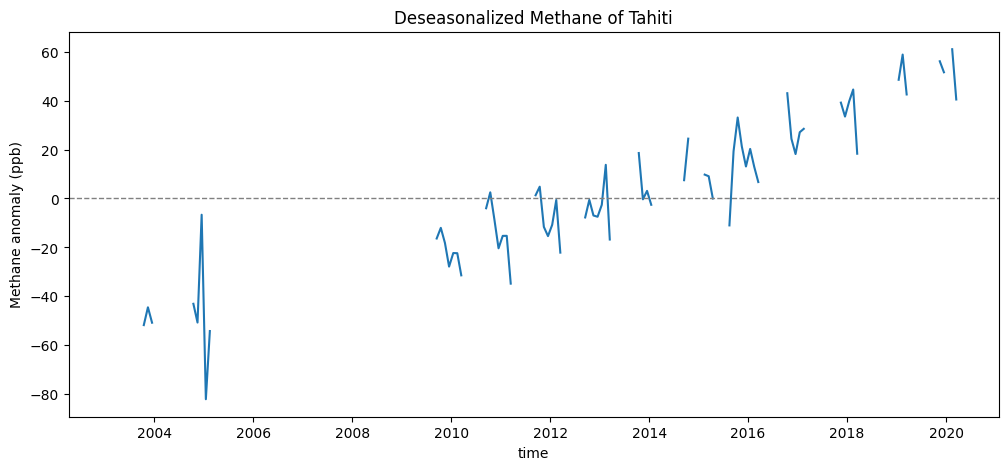

In [109]:
## 1.3 Tahiti deseasonalized 
Tahiti = methane2.sel(lat= -15, lon = -150, method = 'nearest')
climatologi = Tahiti.groupby('time.month').mean(dim = 'time')
deseasonalized = Tahiti.groupby('time.month') - climatologi
deseasonalized.plot(figsize = (12,5))
plt.ylabel("Methane anomaly (ppb)")
plt.title("Deseasonalized Methane of Tahiti")
## 绘制一条水平参考线
plt.axhline(y=0, color="gray", linestyle="--", linewidth=1)
plt.show()

In [69]:
## 2.1 monthly climatology
data1 = xr.open_dataset(
    r"NOAA_NCDC_ERSST_v3b_SST.nc",
    engine="netcdf4"
)

nino_34 = data1['sst'].sel(
    lat = slice(-5,5),
    lon = slice(190,240)
)
monthly_climatology = nino_34.groupby('time.month').mean(dim = 'time')
monthly_anomaly =  nino_34.groupby('time.month') - monthly_climatology

#monthly_climatology
monthly_anomaly

<xarray.DataArray 'sst' (time: 684, lat: 5, lon: 26)> Size: 356kB
array([[[-0.43157768, -0.41846275, -0.39795303, ..., -0.2116642 ,
         -0.23776245, -0.24401474],
        [-0.41259003, -0.4067192 , -0.3875141 , ..., -0.52064896,
         -0.5346451 , -0.51997185],
        [-0.40932274, -0.39743805, -0.36237717, ..., -0.6373882 ,
         -0.6171951 , -0.583725  ],
        [-0.4140854 , -0.37909317, -0.3215618 , ..., -0.43292618,
         -0.38404274, -0.3352623 ],
        [-0.5043678 , -0.43894005, -0.3710251 , ..., -0.17453575,
         -0.11044502, -0.06918144]],

       [[-0.5374584 , -0.52739716, -0.50823593, ..., -0.40254593,
         -0.44382668, -0.45287704],
        [-0.55093956, -0.539135  , -0.51673317, ..., -0.6660595 ,
         -0.7127285 , -0.710968  ],
        [-0.61242104, -0.5959244 , -0.5572338 , ..., -0.7235069 ,
         -0.7326374 , -0.73106194],
        [-0.6798363 , -0.6483364 , -0.5889931 , ..., -0.5397434 ,
         -0.50793266, -0.49977684],
        [-0.7830448 , -0.7286701 , -0.6683655 , ..., -0.33967972,
...
         -0.2555828 , -0.13972664],
        [-0.989378  , -1.0497723 , -1.0954857 , ..., -0.86087227,
         -0.7690697 , -0.65498734],
        [-1.1887245 , -1.252285  , -1.3029232 , ..., -1.0460625 ,
         -0.9661274 , -0.8785801 ],
        [-1.002367  , -1.0756893 , -1.1325111 , ..., -0.7207298 ,
         -0.6597252 , -0.5900669 ],
        [-0.5770798 , -0.65514374, -0.72174263, ..., -0.4353485 ,
         -0.36265945, -0.28103828]],

       [[-0.3578701 , -0.41542053, -0.47110367, ..., -0.2400589 ,
         -0.1464405 , -0.03788376],
        [-0.7678585 , -0.83501625, -0.9024124 , ..., -0.727829  ,
         -0.61603355, -0.48027992],
        [-0.96187973, -1.0445309 , -1.1224213 , ..., -0.9327831 ,
         -0.81235695, -0.6655674 ],
        [-0.82112694, -0.9206734 , -1.0085506 , ..., -0.6531601 ,
         -0.5626869 , -0.4374504 ],
        [-0.4864292 , -0.5823746 , -0.6702862 , ..., -0.36221695,
         -0.30041504, -0.1987915 ]]], shape=(684, 5, 26), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1960-01-15 1960-02-15 ... 2016-12-15
    month    (time) int64 5kB 1 2 3 4 5 6 7 8 9 10 11 ... 3 4 5 6 7 8 9 10 11 12
  * lat      (lat) float32 20B -4.0 -2.0 0.0 2.0 4.0
  * lon      (lon) float32 104B 190.0 192.0 194.0 196.0 ... 236.0 238.0 240.0
Attributes:
    pointwidth:          1.0
    valid_min:           -3.0
    valid_max:           45.0
    units:               degree_Celsius
    long_name:           Extended reconstructed sea surface temperature
    standard_name:       sea_surface_temperature
    iridl:hasSemantics:  iridl:SeaSurfaceTemperature

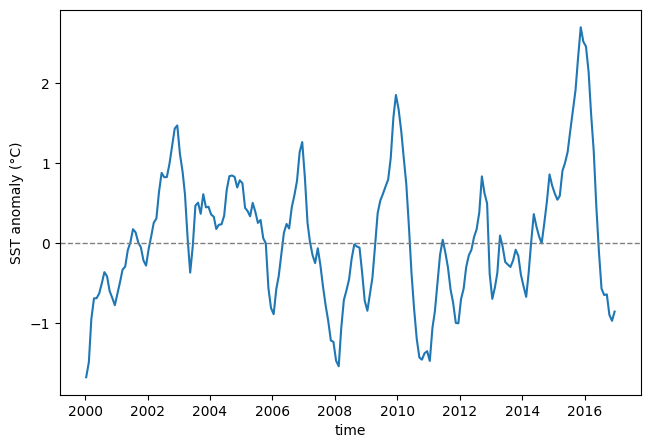

In [70]:
#2.2 plotting
## 调整区域面积权重
## 绘制一维时间序列

weights = np.cos(np.deg2rad(monthly_anomaly["lat"]))
nino34_index = monthly_anomaly.weighted(weights).mean(dim=["lat", "lon"])

## 截取参考结果的时间段
time2 = data1["time"].sel(time=slice("2000", "2020"))
nino34_index2 = nino34_index.sel(time=time2)

nino34_index2.plot(figsize=(7.5, 5))
plt.ylabel("SST anomaly (°C)")
## 绘制一条水平参考线
plt.axhline(y=0, color="gray", linestyle="--", linewidth=1)
plt.show()



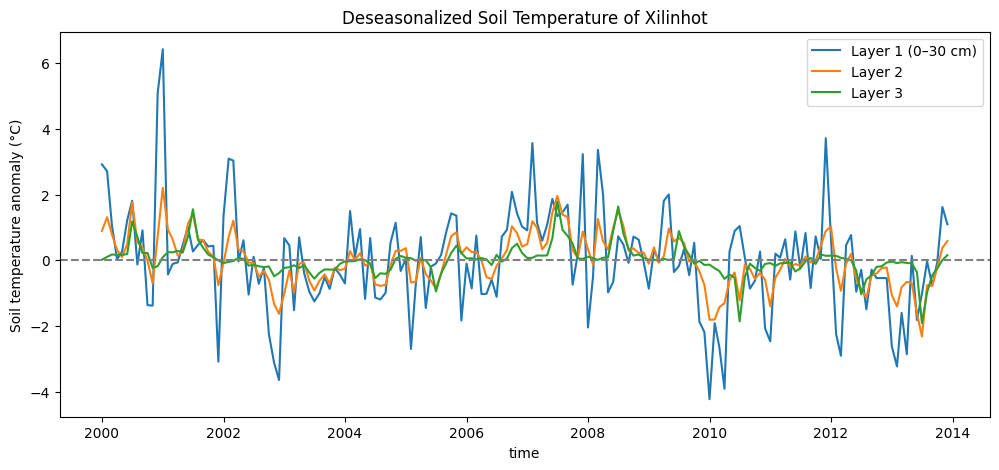

In [82]:
## 3.1 soil temperature time series
soildata = xr.open_dataset(
    r"GLDAS_VIC10_M_2.0_2000_2013.nc",
    engine="netcdf4"
)

#print(soildata.data_vars)
#for name, var in soildata.data_vars.items():
#    print(
#        name,
#        "|", var.attrs.get("long_name", "无描述"),
#        "|", var.attrs.get("units", "未标注单位")
#    )
##选择三个土层的土壤温度数据
variables = [
    "SoilTMP0_30cm_inst",
    "SoilTMP_depth2_inst",
    "SoilTMP_depth3_inst"
]
# 选取锡林浩特市最接近的经纬点
Xilinhot = soildata[variables].sel(
    lat= 43.933411,
    lon= 116.086032,
    method='nearest'
)
# 转换开尔文温度
Xilinhot = Xilinhot - 273.15
for name in variables:
    Xilinhot[name].attrs["units"] = "°C"

#print(Xilinhot)

climatology = Xilinhot.groupby("time.month").mean(dim="time")
anomaly = Xilinhot.groupby("time.month") - climatology
plt.figure(figsize=(12, 5))

for name, label in zip(variables, ["Layer 1 (0–30 cm)", "Layer 2", "Layer 3"]):
    anomaly[name].plot(label=label)

plt.axhline(0, color="gray", linestyle="--")
plt.ylabel("Soil temperature anomaly (°C)")
plt.title("Deseasonalized Soil Temperature of Xilinhot")
plt.legend()
plt.show()

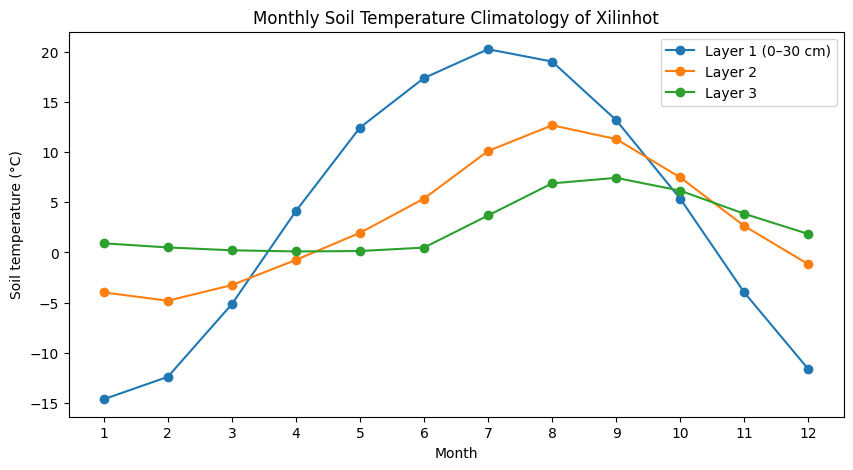

In [110]:
## 3.2 different plots
## [1] monthly climatology curves of soil temperature
variables = [
    "SoilTMP0_30cm_inst",
    "SoilTMP_depth2_inst",
    "SoilTMP_depth3_inst"
]

labels = ["Layer 1 (0–30 cm)", "Layer 2", "Layer 3"]
climatology = Xilinhot.groupby("time.month").mean(dim="time")
plt.figure(figsize=(10, 5))

for name, label in zip(variables, labels):
    climatology[name].plot(marker="o", label=label)

plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Soil temperature (°C)")
plt.title("Monthly Soil Temperature Climatology of Xilinhot")
plt.legend()
plt.show()

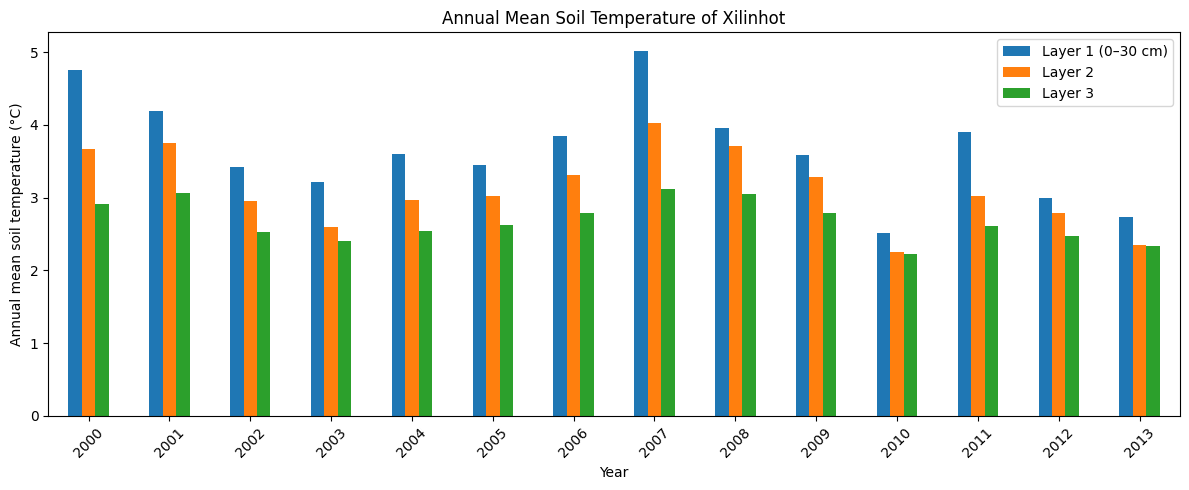

In [100]:
## 3.2 
## [2] annual mean Temperature bar plot
annual = Xilinhot.groupby("time.year").mean(dim="time")

annual_df = annual[variables].to_dataframe()[variables]
annual_df.columns = labels

ax = annual_df.plot.bar(
    figsize=(12, 5),
    rot=45
)

ax.set_xlabel("Year")
ax.set_ylabel("Annual mean soil temperature (°C)")
ax.set_title("Annual Mean Soil Temperature of Xilinhot")
plt.tight_layout()
plt.show()

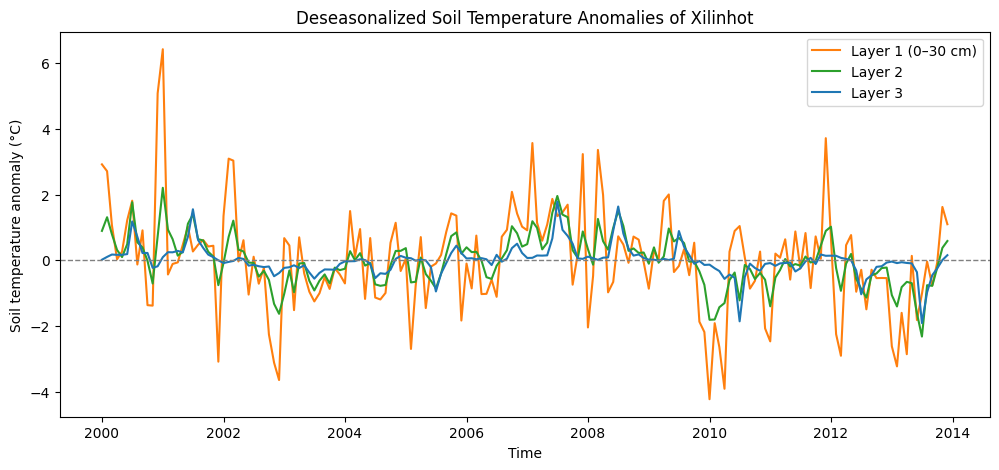

In [111]:
## 3.2 
## [3] anomaly time series curves of soil temperature
# 各土层的逐月气候态和距平时间序列
climatology = Xilinhot[variables].groupby("time.month").mean(dim="time")
temp_anomaly = Xilinhot[variables].groupby("time.month") - climatology

plt.figure(figsize=(12, 5))

for name, label, color in zip(variables, labels, colors):
    temp_anomaly[name].plot(label=label, color=color)

plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.xlabel("Time")
plt.ylabel("Soil temperature anomaly (°C)")
plt.title("Deseasonalized Soil Temperature Anomalies of Xilinhot")
plt.legend()
plt.show()

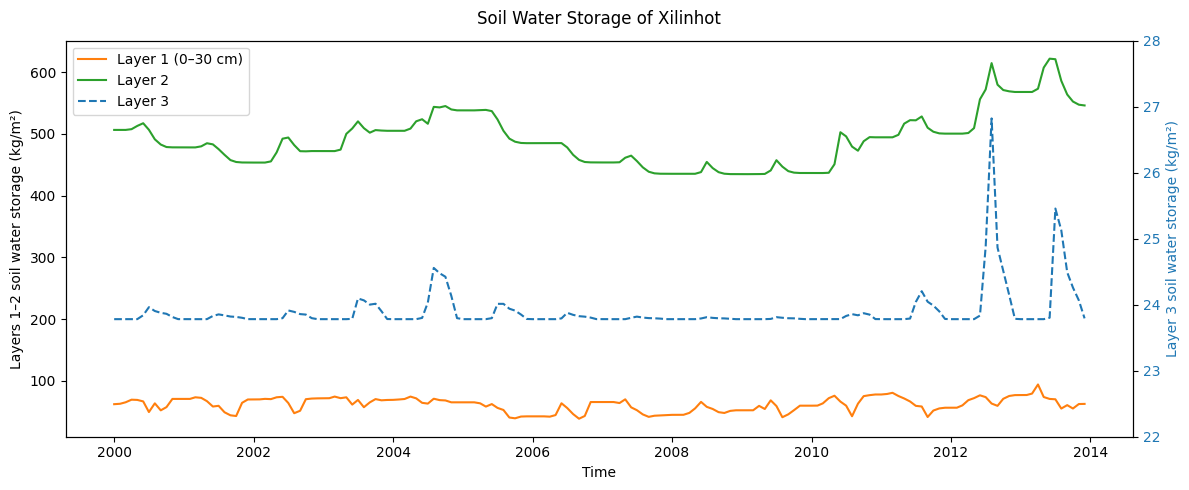

In [113]:
## 3.2 
## [4] soil moiture time series twinx curves
moisture_vars = [
    "SoilMoi0_30cm_inst",
    "SoilMoi_depth2_inst",
    "SoilMoi_depth3_inst"
]

# 对应土壤温度的经纬点
moisture = soildata[moisture_vars].sel(
    lat=Xilinhot.lat,
    lon=Xilinhot.lon,
    time=Xilinhot.time
)

colors = ["tab:orange", "tab:green", "tab:blue"]

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

# 第一、二层：左轴
for name, label, color in zip(
    moisture_vars[:2], labels[:2], colors[:2]
):
    moisture[name].plot(ax=ax1, label=label, color=color)

# 第三层：右轴
moisture[moisture_vars[2]].plot(
    ax=ax2,
    label=labels[2],
    color=colors[2],
    linestyle="--"
)

# 清除 xarray 自动生成的标题
ax1.set_title("")
ax2.set_title("")

ax1.set_xlabel("Time")
ax1.set_ylabel("Layers 1–2 soil water storage (kg/m²)")
ax2.set_ylabel("Layer 3 soil water storage (kg/m²)", color=colors[2])
ax2.tick_params(axis="y", labelcolor=colors[2])

# 合并图例
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)
ax2.set_ylim(22, 28)
ax1.set_title("Soil Water Storage of Xilinhot", pad=12)
plt.tight_layout()
plt.show()

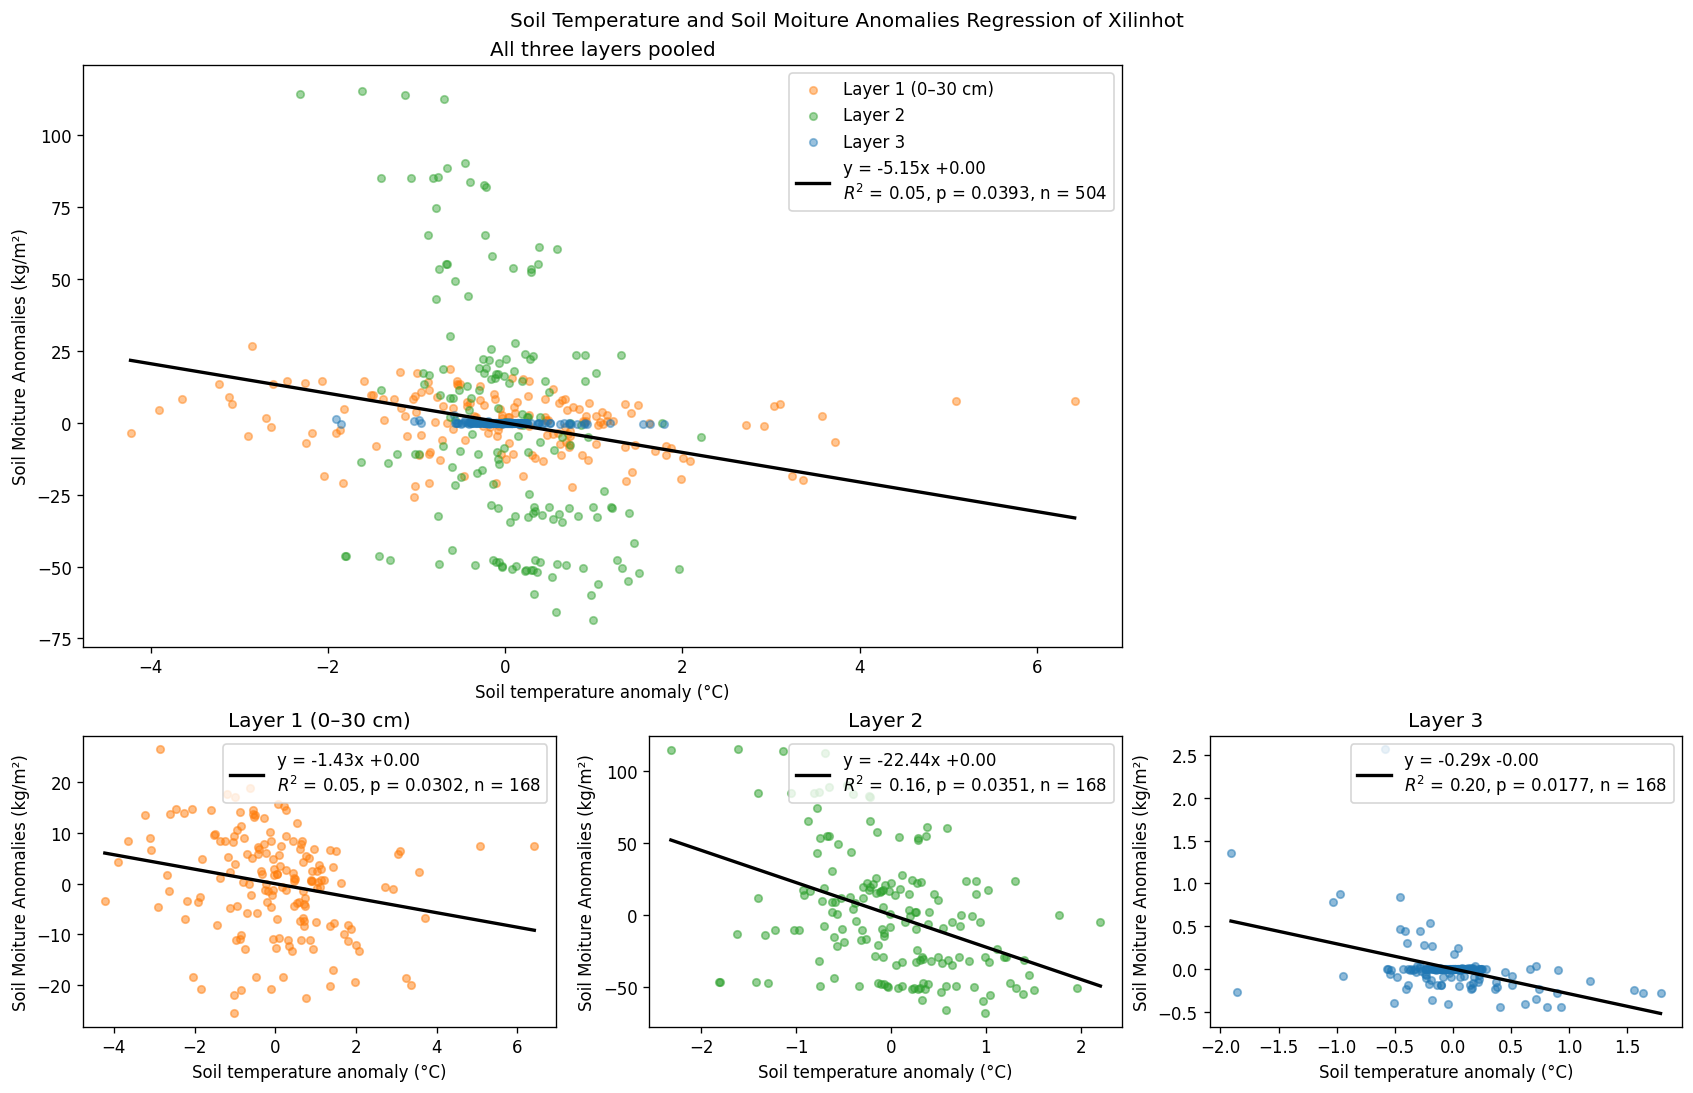

                    Fit   Slope  Intercept  R_squared  P_value  Significant  N_pairs  N_months    SE_method
All three layers pooled  -5.146  5.881e-06     0.0453  0.03927         True      504       168 HAC by month
      Layer 1 (0–30 cm)  -1.431  1.772e-06    0.05145  0.03018         True      168       168          HAC
                Layer 2  -22.44  1.497e-05     0.1636  0.03506         True      168       168          HAC
                Layer 3 -0.2924 -2.586e-07     0.1975  0.01768         True      168       168          HAC


In [119]:
## 3.2 
## [5] moiture vs temperature regression panels

#检验回归模型
import statsmodels.api as sm

#分别定义温度、湿度变量
temp_vars = [
    "SoilTMP0_30cm_inst",
    "SoilTMP_depth2_inst",
    "SoilTMP_depth3_inst"
]

mois_vars = [
    "SoilMoi0_30cm_inst",
    "SoilMoi_depth2_inst",
    "SoilMoi_depth3_inst"
]
labels = ["Layer 1 (0–30 cm)", "Layer 2", "Layer 3"]
colors = ["tab:orange", "tab:green", "tab:blue"]

#分别去除温度和湿度的月度季节循环
temp_group = Xilinhot[temp_vars].sortby("time").groupby("time.month")
mois_group = moisture[mois_vars].sortby("time").groupby("time.month")

temp_anom = temp_group - temp_group.mean("time", skipna=True)
mois_anom = mois_group - mois_group.mean("time", skipna=True)

#对齐温度和湿度的时间坐标
temp_anom, mois_anom = xr.align(temp_anom, mois_anom, join="exact")

fig = plt.figure(figsize=(14, 9), dpi=120, layout="constrained")
#采用网格方法绘制不规则子图
ax_all = plt.subplot2grid((3, 3), (0, 0), rowspan=2, colspan=2, fig=fig)
axes = [plt.subplot2grid((3, 3), (2, col), fig=fig) for col in range(3)]
#大图 2×3 小图 1×1

results = []
layer_data = []
maxlags = 12  #HAC标准误最多考虑 12 个月的滞后

#定义用于回归分析的函数
def draw_fit(ax, data, model, title, se_method):
    
    intercept, slope = model.params
    p = model.pvalues[1]
    r2 = model.rsquared
    x_line = np.linspace(data["temp"].min(), data["temp"].max(), 100)

    ax.plot(
        x_line,
        intercept + slope * x_line,
        color="black",
        linewidth=2,
        linestyle="-" if p < 0.05 else "--",
        label=(
            f"y = {slope:.2f}x {intercept:+.2f}\n"
            f"$R^2$ = {r2:.2f}, p = {p:.3g}, n = {len(data)}"
        ),
    )
    ax.set(
        title=title,
        xlabel="Soil temperature anomaly (°C)",
        ylabel="Soil Moiture Anomalies (kg/m²)",
    )
    ax.legend()

    results.append({
        "Fit": title,
        "Slope": slope,
        "Intercept": intercept,
        "R_squared": r2,
        "P_value": p,
        "Significant": p < 0.05,
        "N_pairs": len(data),
        "N_months": data["month_id"].nunique(),
        "SE_method": se_method,
    })

#整理月份编号，以便后续检查是否存在缺失月份
month_id = (temp_anom.time.dt.year * 12 + temp_anom.time.dt.month).values

#逐层进行回归拟合
for ax, tvar, mvar, label, color in zip(
    axes, temp_vars, mois_vars, labels, colors
):
    x = temp_anom[tvar].values
    y = mois_anom[mvar].values
    ##检查缺失值
    valid = np.isfinite(x) & np.isfinite(y)

    ##整理dataframe数据集便于作图
    data = pd.DataFrame({
        "temp": x[valid],
        "moisture": y[valid],
        "month_id": month_id[valid],
    })

    if len(data) <= maxlags or data["temp"].nunique() < 2:
        raise ValueError(f"{label}: 有效数据不足，无法拟合。")
    if not np.all(np.diff(data["month_id"].to_numpy()) == 1):
        raise ValueError(f"{label}: 有效月份不连续，请检查缺月或重复月份。")

    ##回归分析采用的模型
    model = sm.OLS(
        data["moisture"].to_numpy(),
        sm.add_constant(data["temp"].to_numpy()),
    ).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})

    ##绘制散点图  alpha为散点透明度 s为散点大小
    ax.scatter(data["temp"], data["moisture"], color=color, alpha=0.5, s=20)
    draw_fit(ax, data, model, label, "HAC")

    ax_all.scatter(
        data["temp"], data["moisture"],
        color=color, alpha=0.45, s=20, label=label,
    )
    layer_data.append(data)

#.concat 合并土层 
#ignore_index=True 会重新生成行索引，月份信息保留在 month_id 列中。
pooled = pd.concat(layer_data, ignore_index=True).sort_values("month_id")
pooled_month = pooled["month_id"].to_numpy()
pooled_month = pooled_month - pooled_month.min()

pooled_model = sm.OLS(
    pooled["moisture"].to_numpy(),
    sm.add_constant(pooled["temp"].to_numpy()),
).fit(
     # 按月份来估计稳健标准误
    cov_type="hac-groupsum",
    cov_kwds={
        "time": pooled_month,
        "maxlags": maxlags,     #最多考虑12个月的滞后
        "df_correction": False, #固定自由度
    },
)

draw_fit(ax_all, pooled, pooled_model, "All three layers pooled", "HAC by month")

fig.suptitle("Soil Temperature and Soil Moiture Anomalies Regression of Xilinhot")
plt.show()

#查看统计结果
regression_results = pd.DataFrame([results[-1], *results[:-1]])
print(regression_results.to_string(index=False, float_format=lambda v: f"{v:.4g}"))